# 03 · Hedge dynamique, signal & backtest

**Objectif** : hedge dynamique (Kalman), signal z-score, backtest sans look-ahead, contrôle de risque, et comparaison walk-forward / split simple.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
from src import (data_loader as dl, features as ft, stats_tests as st,
                 hedge_ratio as hr, signal as sig, backtest as bt, metrics as mt,
                 curve as cv, regime as rg, pipeline as pl)
from src.config import StrategyConfig, MARKET_EVENTS, REGIME_SEGMENTS
def events(ax):
    for e in MARKET_EVENTS:
        ax.axvline(pd.Timestamp(e["date"]), color="gray", ls=":", lw=1, alpha=.6)

prices = dl.get_prices('futures')
cfg = StrategyConfig(hedge_method='kalman')

### Hedge ratio dynamique (Kalman) & signal

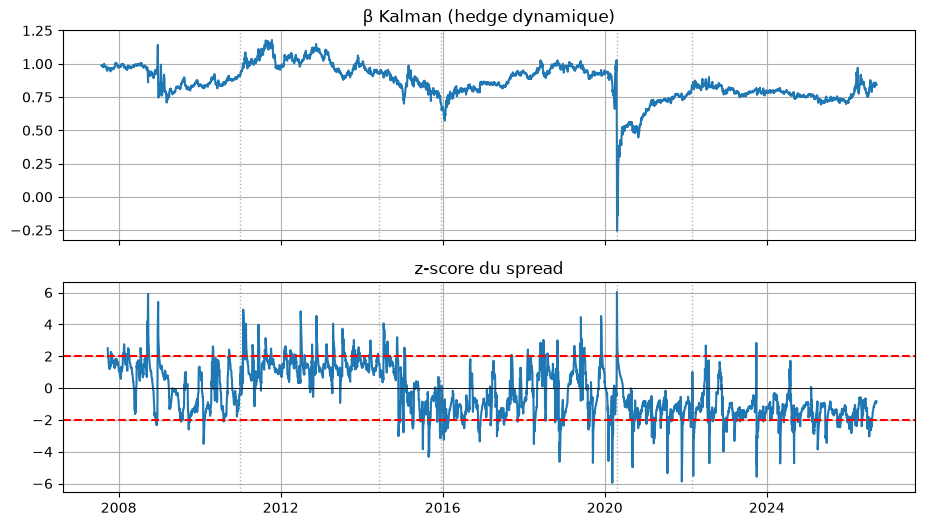

In [2]:
hedge = hr.compute_hedge(prices, cfg)
s = sig.build_signal(prices, hedge, cfg)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(hedge.index, hedge['beta']); ax[0].set_title('β Kalman (hedge dynamique)'); events(ax[0])
ax[1].plot(s.index, s['zscore']); ax[1].axhline(2, color='r', ls='--'); ax[1].axhline(-2, color='r', ls='--')
ax[1].axhline(0, color='k', lw=.6); ax[1].set_title('z-score du spread'); events(ax[1]); plt.show()

### Backtest : brut vs risk-managed (vol-target 10 %) vs Buy & Hold

BRUT        : {'sharpe': 0.446, 'ann_return': 0.041, 'ann_vol': 0.091, 'max_drawdown': -0.203}
RISK-MANAGED: {'sharpe': 0.453, 'ann_return': 0.045, 'ann_vol': 0.099, 'max_drawdown': -0.201}
B&H (CAGR)  : {'sharpe': 0.239, 'ann_return': 0.018, 'ann_vol': 0.384, 'max_drawdown': -0.868}


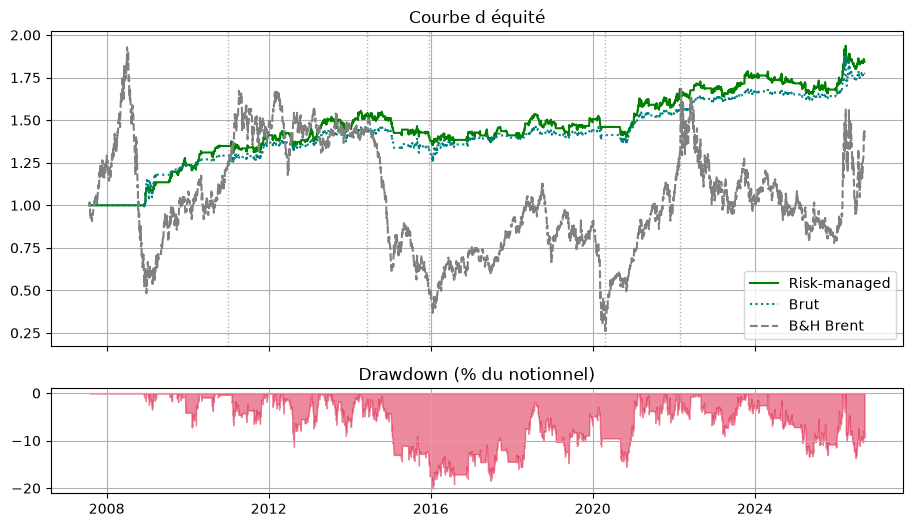

In [3]:
out = pl.run_strategy(prices, cfg, vol_target=0.10)
keys = ['sharpe','ann_return','ann_vol','max_drawdown']
print('BRUT        :', {k: round(out['metrics_raw'][k],3) for k in keys})
print('RISK-MANAGED:', {k: round(out['metrics_rm'][k],3) for k in keys})
print('B&H (CAGR)  :', {k: round(out['bh_metrics'][k],3) for k in keys})
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={'height_ratios':[3,1]})
ax[0].plot(out['equity_rm'], label='Risk-managed', color='green')
ax[0].plot(out['equity_raw'], label='Brut', color='teal', ls=':')
ax[0].plot(out['bh_equity'], label='B&H Brent', color='gray', ls='--')
ax[0].legend(); ax[0].set_title('Courbe d équité'); events(ax[0])
dd = mt.drawdown_series(out['returns_rm'], compound=False)
ax[1].fill_between(dd.index, dd*100, 0, color='crimson', alpha=.5); ax[1].set_title('Drawdown (% du notionnel)'); plt.show()

### Garde-fou d'entrée : le trade du WTI négatif
Le 20/04/2020 le Kalman produit β < 0 : sans garde-fou, le trade ouvert le lendemain est une vente sèche de Brent.

In [4]:
print(hedge['beta'].loc['2020-04-15':'2020-04-24'].round(3))
s_ng = s.copy(); s_ng['position'] = sig.generate_signals(s['zscore'], cfg)  # sans garde-fou
r_ng = bt._simulate(prices, s_ng, cfg)
print('Sharpe brut sans garde-fou :', round(mt.sharpe(r_ng.returns),2), '| avec :', round(mt.sharpe(out['returns_raw']),2))
print(r_ng.trades.nsmallest(1, 'net')[['entry_date','side','beta','net']])

date
2020-04-15    0.947
2020-04-16    0.951
2020-04-17    1.023
2020-04-20   -0.017
2020-04-21   -0.255
2020-04-22   -0.122
2020-04-23   -0.039
2020-04-24   -0.029
Name: beta, dtype: float64
Sharpe brut sans garde-fou : 0.08 | avec : 0.45
   entry_date  side      beta      net
55 2020-04-21    -1 -0.016537 -0.58214


### Walk-forward continu vs split simple — sur les MÊMES périodes
Comparer l'in-sample d'une méthode (2008-2017) à l'out-of-sample (2018+) mélange l'effet « méthode » et l'effet « période » : on compare donc les trois méthodes sur les deux mêmes fenêtres.

In [5]:
wf = bt.backtest_walk_forward_blocks(prices, cfg)
sp = bt.backtest_simple_split(prices, cfg, split='2018-01-01')
cut = pd.Timestamp('2018-01-01')
rows = {'Kalman en ligne': out['returns_raw'], 'blocs trimestriels': wf.returns,
        'split unique (β figé)': sp['result'].returns}
display(pd.DataFrame({k: {'< 2018': mt.sharpe(r[r.index < cut]), '>= 2018': mt.sharpe(r[r.index >= cut])}
                      for k, r in rows.items()}).T.round(2))

,< 2018,>= 2018
Kalman en ligne,0.45,0.45
blocs trimestriels,0.69,0.14
split unique (β figé),0.63,0.11


### Sensibilité (Sharpe risk-managed) — pas de sur-optimisation

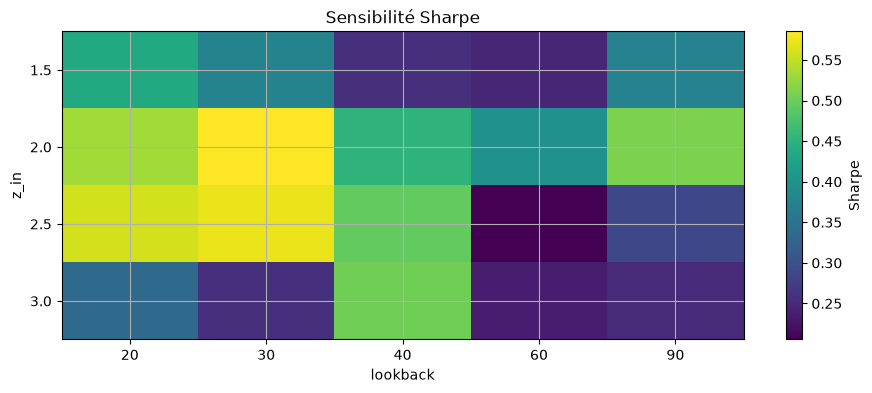

,20,30,40,60,90
1.5,0.44,0.37,0.26,0.25,0.37
2.0,0.53,0.59,0.45,0.40,0.51
2.5,0.56,0.57,0.49,0.21,0.29
3.0,0.34,0.26,0.50,0.23,0.25


In [6]:
from dataclasses import replace
z_ins=[1.5,2.0,2.5,3.0]; lbs=[20,30,40,60,90]
grid=pd.DataFrame(index=z_ins, columns=lbs, dtype=float)
for zi in z_ins:
    for lb in lbs:
        grid.loc[zi,lb]=mt.sharpe(pl.run_strategy(prices, replace(cfg,z_in=zi,z_lookback=lb), vol_target=0.10)['returns_rm'])
im=plt.imshow(grid.values.astype(float), cmap='viridis', aspect='auto')
plt.xticks(range(len(lbs)), lbs); plt.yticks(range(len(z_ins)), z_ins)
plt.xlabel('lookback'); plt.ylabel('z_in'); plt.colorbar(im, label='Sharpe'); plt.title('Sensibilité Sharpe'); plt.show()
display(grid.round(2))

### Performance par régime

In [7]:
rb = pl.regime_breakdown(out['returns_rm'], REGIME_SEGMENTS)
display(rb[['regime','sharpe','pnl','max_dd','n_days']].round(3))

,regime,sharpe,pnl,max_dd,n_days
0,Pré-glut (2007-2010),1.397,0.348,-0.072,842
1,WTI discount / Cushing glut (2011-2014),0.542,0.176,-0.113,848
2,Krach & export ban (2014-2016),-0.403,-0.097,-0.196,630
3,Normalisation (2017-2019),0.294,0.080,-0.128,754
4,COVID & reprise (2020-2021),0.395,0.081,-0.126,505
5,Guerre & inflation (2022+),0.464,0.257,-0.137,1182


**Lecture** : à période égale, seules les méthodes à β constant (split, blocs) perdent leur performance après 2018 ; le Kalman en ligne la conserve (≈ 0,45 / 0,45). Une fois le trade aberrant du WTI négatif écarté, le signal brut a un Sharpe ≈ 0,45 ; le vol-target fixe le risque (vol ≈ 10 %) **sans changer le Sharpe**. Le vrai mode de casse reste 2014-2016.